# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

1. Список окремих віршів зберігає межі документів і не потребує великої копії склеєного тексту. Передати `[corpus_text]` можна, але межі документів буде втрачено. Якщо ж передати просто `corpus_text`, ітератор повертатиме окремі символи: тренер не побачить звичайних сусідніх підслів і не навчить нормальні BPE-злиття.

2. Токенізація складається з нормалізації тексту, попереднього поділу на фрагменти, розбиття цих фрагментів на токени та перетворення в id. Після цього post-processing додає потрібні службові токени. Декодер виконує зворотне перетворення id у текст.

2. `<unk>` позначає невідомий токен, а `<eos>` — кінець документа.

3. Для словника 16000 середня довжина становила 1027.91 токена на вірш, для 4000 — 1251.30, тобто зросла приблизно у 1.22 раза. В обох випадках частка `<unk>` дорівнювала 0%. Byte-level BPE з повним алфавітом байтів може закодувати будь-який UTF-8 текст, але з меншим словником частіше розбиває слова на дрібніші частини. Тому той самий `CONTEXT_LEN` охоплює менше тексту.

4. `<eos>` показує межу між документами. Без нього модель навчатиметься продовжувати останні слова одного вірша початком наступного і не матиме явного сигналу завершення тексту.

5. У демо це одновимірні тензори `torch.int64`. Кожен елемент — індекс токена у словнику, а не слово чи embedding.

6. Перевірка зміщення батчу: `assert torch.equal(x[:, 1:], y[:, :-1])`. У функції `get_batch` також перевірено останній target через початкові індекси вікон.

7. Нижній трикутник дозволяє позиції `t` бачити лише попередні токени та себе. Верхній відкрив би майбутні токени й закрив минулі. Без маски модель підглядатиме правильну відповідь під час навчання, хоча при генерації майбутніх токенів ще немає.

8. Чекпоінти збігаються, якщо остання оцінка дає найменший `val_loss`. При перенавчанні чи коливаннях вони можуть відрізнятися. У v1 і v2 найкращим був останній крок 4000. У v3_long мінімум був на кроці 7750 додаткового навчання, а не на останньому кроці 8000.

10. При інтервалі 50 крива стала щільнішою й інформативнішою, але не обов'язково гладкішою. У контрольних прогонах по 500 кроків повний час зріс приблизно з 9.54 до 12.75 с, а час оцінювання — з 0.63 до 2.45 с. Додалося 320 eval forward-батчів. Ще менший інтервал збільшуватиме витрати, не покращуючи саме навчання.

11. Температура ділить логіти перед softmax: `p_i = exp(z_i / T) / sum_j exp(z_j / T)`. Мала температура посилює перевагу найімовірніших токенів. При дуже великій температурі розподіл наближається до рівномірного, тому текст стає випадковішим.

12. `top_p` залишає найменшу множину найімовірніших токенів із сумарною ймовірністю не меншою за `p`, перенормовує їхні ймовірності й семплює серед них. Кількість кандидатів залежить від контексту.

13. При `enable_thinking=False` модель одразу дала коротку відповідь `17 * 23 = 391`. При `True` з'явився блок `<think>` з поясненням обчислення. Він використав весь бюджет 160 токенів, тому генерація обірвалася до завершеної фінальної відповіді. Такий режим потребував більше часу й токенів.


In [ ]:
import sys, os, subprocess, importlib.util, importlib.metadata
from pathlib import Path
if not (3, 10) <= sys.version_info[:2] < (3, 14):
    raise RuntimeError('Потрібен kernel Python 3.10–3.13.')
IN_COLAB = importlib.util.find_spec('google.colab') is not None if importlib.util.find_spec('google') else False
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/ai_systems/lab3')
    HF_CACHE = Path('/content/lab3_cache/huggingface')
else:
    BASE = Path.cwd() if Path.cwd().name == 'lab3' else Path.cwd() / 'lab3'
    HF_CACHE = BASE / 'cache' / 'huggingface'
BASE.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('HF_HOME', str(HF_CACHE))
os.environ.setdefault('TOKENIZERS_PARALLELISM', 'false')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')
os.environ.setdefault('GRADIO_ANALYTICS_ENABLED', 'False')
os.environ.setdefault('USE_TF', '0')
os.environ.setdefault('USE_FLAX', '0')

def pip_install(*args):
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', '--progress-bar', 'off',
                             '--only-binary=sentencepiece', *args],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if result.returncode:
        print(result.stdout)
        raise RuntimeError('Не вдалося встановити бібліотеки. Повідомлення pip наведене вище.')
    print('\n'.join(result.stdout.splitlines()[-12:]))

if importlib.util.find_spec('packaging') is None:
    pip_install('packaging>=23')
from packaging.requirements import Requirement
requirements = ['transformers==4.57.1', 'tokenizers==0.22.1', 'datasets==3.6.0',
                'evaluate==0.4.6', 'gradio==5.49.1', 'huggingface-hub==0.36.2',
                'numpy>=2.2.6,<3', 'pandas>=2.2.3,<3', 'matplotlib>=3.10.3,<4',
                'scikit-learn>=1.6.1,<2', 'tensorboard>=2.19.0,<3',
                'sentencepiece==0.2.1' if sys.version_info >= (3, 13) else 'sentencepiece==0.2.0',
                'protobuf>=5.29.5,<7', 'fsspec==2025.3.0']
if sys.version_info >= (3, 13):
    requirements.append('audioop-lts==0.2.2')
missing = []
loaded_before = {}
module_names = {'scikit-learn': 'sklearn', 'huggingface-hub': 'huggingface_hub',
                'protobuf': 'google.protobuf', 'audioop-lts': 'audioop'}
for item in requirements:
    req = Requirement(item)
    try:
        version = importlib.metadata.version(req.name)
        if version not in req.specifier:
            missing.append(item)
            if module_names.get(req.name, req.name) in sys.modules:
                loaded_before[req.name] = version
    except importlib.metadata.PackageNotFoundError:
        missing.append(item)
if missing:
    pip_install(*missing)
changed_loaded = [name for name, version in loaded_before.items()
                  if importlib.metadata.version(name) != version]
if changed_loaded:
    raise RuntimeError('Оновлено вже імпортовані пакети: ' + ', '.join(changed_loaded)
                       + '. Виконайте Runtime → Restart session, потім Run All. Код змінювати не потрібно.')

gpu_present = subprocess.run(['nvidia-smi', '-L'], capture_output=True).returncode == 0 if __import__('shutil').which('nvidia-smi') else False
if importlib.util.find_spec('torch') is None:
    pip_install('torch==2.8.0', '--index-url', 'https://download.pytorch.org/whl/cu128' if gpu_present else 'https://download.pytorch.org/whl/cpu')
import torch
if os.name == 'nt':
    import sentencepiece as spm
    if not getattr(spm.SentencePieceProcessor, '_unicode_path_fix', False):
        _sp_load = spm.SentencePieceProcessor.LoadFromFile
        def _sp_unicode_load(self, filename):
            if isinstance(filename, (str, os.PathLike)) and Path(filename).is_file():
                return self.LoadFromSerializedProto(Path(filename).read_bytes())
            return _sp_load(self, filename)
        spm.SentencePieceProcessor.LoadFromFile = _sp_unicode_load
        spm.SentencePieceProcessor._unicode_path_fix = True
if gpu_present and (not torch.cuda.is_available() or (torch.cuda.get_device_capability()[0] >= 12 and tuple(map(int, (torch.version.cuda or '0.0').split('.')[:2])) < (12, 8))):
    pip_install('torch==2.8.0', '--index-url', 'https://download.pytorch.org/whl/cu128', '--upgrade')
    raise RuntimeError('Оновлено PyTorch для GPU. Перезапустіть kernel і виконайте Run All; код змінювати не потрібно.')
print('Python:', sys.version.split()[0], '| torch:', torch.__version__, '| Colab:', IN_COLAB)
print('Артефакти:', BASE.resolve())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python: 3.13.16 | torch: 2.11.0+cu130 | Colab: True
Артефакти: /content/drive/MyDrive/ai_systems/lab3


In [ ]:
import gc, math, time, random, json, hashlib, copy, contextlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display, Markdown
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers
from torch.utils.tensorboard import SummaryWriter
from transformers import AutoTokenizer, pipeline, set_seed

SEED = 42
set_seed(SEED)
torch.set_num_threads(min(8, os.cpu_count() or 2))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cuda':
    torch.backends.cuda.matmul.allow_tf32 = True
    print(torch.cuda.get_device_name(), '| VRAM:', round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1), 'GiB')
print('Пристрій:', device)
MODELS = BASE / 'models'; RUNS = BASE / 'runs'; REPORTS = BASE / 'reports'
for folder in (MODELS, RUNS, REPORTS, BASE / 'tokenizers'): folder.mkdir(exist_ok=True)
SPECIAL = ['<unk>', '<eos>']
MODEL_IDS = {
    'sentiment': 'cardiffnlp/twitter-xlm-roberta-base-sentiment',
    'zero_small': 'MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli',
    'zero_base': 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli',
    'generation': 'Qwen/Qwen3-0.6B',
    'mask': 'FacebookAI/xlm-roberta-base',
    'ner': 'ukr-models/uk-ner',
    'table': 'google/tapas-base-finetuned-wtq',
}
def cleanup():
    gc.collect()
    if device.type == 'cuda': torch.cuda.empty_cache()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize()
def dump_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
        default=lambda x: x.item() if isinstance(x, np.generic) else str(x)), encoding='utf-8')
def make_pipe(task, model_id, **kw):
    return pipeline(task, model=model_id, device=0 if device.type == 'cuda' else -1, **kw)
dump_json(REPORTS / 'environment.json', {'python': platform.python_version(), 'torch': torch.__version__,
          'device': str(device), 'gpu': torch.cuda.get_device_name() if device.type == 'cuda' else None,
          'packages': {Requirement(x).name: importlib.metadata.version(Requirement(x).name) for x in requirements}})


Tesla T4 | VRAM: 14.6 GiB
Пристрій: cuda


In [ ]:
def train_bpe(texts, vocab_size):
    tok = Tokenizer(models.BPE(unk_token='<unk>'))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    tok.train_from_iterator(iter(texts), trainers.BpeTrainer(
        vocab_size=vocab_size, special_tokens=SPECIAL,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(), show_progress=False))
    return tok

poems = load_dataset('RudyiVT/ukrainian-poems', split='train')
poem_texts = [x for x in poems['context_poem'] if isinstance(x, str) and x.strip()]
poem_stats = []
for size in (16000, 4000):
    tok = train_bpe(poem_texts, size)
    counts, unknowns = [], 0
    for start in range(0, len(poem_texts), 256):
        encoded = tok.encode_batch(poem_texts[start:start+256])
        counts.extend(len(x.ids) for x in encoded)
        unknowns += sum(x.ids.count(tok.token_to_id('<unk>')) for x in encoded)
    poem_stats.append({'vocab_requested': size, 'vocab_actual': tok.get_vocab_size(),
                       'tokens_per_poem': np.mean(counts), 'unk_share': unknowns / sum(counts)})
poem_table = pd.DataFrame(poem_stats)
display(poem_table)
poem_table.to_csv(REPORTS / 'demo_bpe_sizes.csv', index=False)
print(f"Зміна середньої довжини: {poem_table.iloc[1].tokens_per_poem / poem_table.iloc[0].tokens_per_poem:.2f}×.")
del poems, poem_texts, tok, encoded
cleanup()


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/695 [00:00<?, ?B/s]

(…)-00000-of-00001-3d92810ccd32069e.parquet:   0%|          | 0.00/58.6M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17918 [00:00<?, ? examples/s]

,vocab_requested,vocab_actual,tokens_per_poem,unk_share
0,16000,16000,1027.913653,0.0
1,4000,4000,1251.304197,0.0


Зміна середньої довжини: 1.22×.


---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

README.md: 0.00B [00:00, ?B/s]

,0
train_docs,3.600000e+04
val_docs,4.000000e+03
train_chars,2.877943e+06
mean_title_chars,7.794292e+01


,train_example
0,"2025 року окупанти хотіли вийти до Одеси, щоб ..."
1,Відомого актора Кіфера Сазерленда заарештували...
2,"Навроцький заявив, що між Польщею та Україною ..."
3,Зеленський обговорив із першим заступником кер...
4,"""Жодного дня не був в Україні"": спливла правда..."
5,Трошки радості зранку: зимові сніданки без еле...
6,У Флоренції театр скасував виступ російських а...
7,"ППО знищила 125 з 154 ворожих БпЛА, зафіксован..."


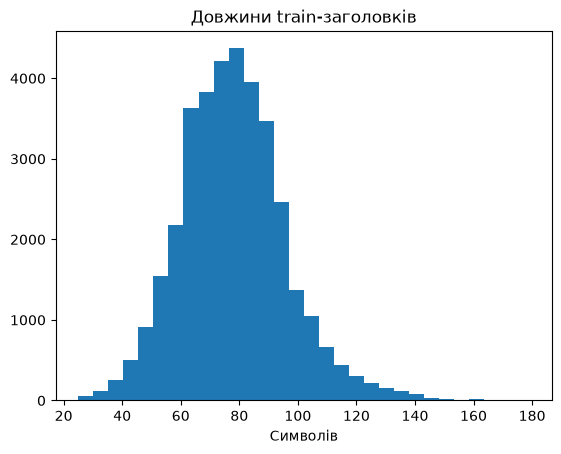

In [ ]:
import re, unicodedata
DATASET_ID = 'JoTalbot/ukrainian-news-2026'
MAX_DOCS = 40000
cache_path = BASE / 'cache' / 'news_titles.json'
cache_path.parent.mkdir(exist_ok=True)
if cache_path.exists():
    titles = json.loads(cache_path.read_text(encoding='utf-8'))
else:
    stream = load_dataset(DATASET_ID, 'deduplicated', split='train', streaming=True)
    stream = stream.shuffle(seed=SEED, buffer_size=5000)
    titles, seen = [], set()
    for row in stream:
        text = re.sub(r'\s+', ' ', unicodedata.normalize('NFC', row.get('title') or '')).strip()
        key = re.sub(r'[^\w]+', '', text.casefold())
        if not 25 <= len(text) <= 180 or not re.search('[іїєґІЇЄҐ]', text) or 'http' in text:
            continue
        if key in seen: continue
        seen.add(key); titles.append(text)
        if len(titles) >= MAX_DOCS: break
    dump_json(cache_path, titles)
assert len(titles) >= 5000, 'Корпус надто малий; перевірте джерело.'
permutation = np.random.default_rng(SEED).permutation(len(titles))
border = int(0.9 * len(titles))
train_texts = [titles[i] for i in permutation[:border]]
val_texts = [titles[i] for i in permutation[border:]]
assert set(train_texts).isdisjoint(val_texts)
corpus_text = '\n\n'.join(train_texts)
CORPUS_HASH = hashlib.sha256('\n'.join(titles).encode()).hexdigest()
dump_json(REPORTS / 'corpus.json', {'dataset': DATASET_ID, 'config': 'deduplicated',
          'column': 'title', 'documents': len(titles), 'train': len(train_texts),
          'val': len(val_texts), 'sha256': CORPUS_HASH, 'seed': SEED})
display(pd.Series({'train_docs': len(train_texts), 'val_docs': len(val_texts),
                   'train_chars': len(corpus_text), 'mean_title_chars': np.mean(list(map(len, train_texts)))}))
display(pd.DataFrame({'train_example': train_texts[:8]}))
plt.hist(list(map(len, train_texts)), bins=30); plt.title('Довжини train-заголовків'); plt.xlabel('Символів'); plt.show()


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [ ]:
warm_base = AutoTokenizer.from_pretrained(MODEL_IDS['generation'])
warm_tokenizer = warm_base.train_new_from_iterator(iter(train_texts[:3000]), vocab_size=2000)
warm_tokenizer.save_pretrained(BASE / 'tokenizers' / 'warmup_qwen')
print('Розминка:', warm_tokenizer.tokenize('В Україні відкрили нову бібліотеку.'))
small_texts = train_texts[:3000]
sample = '\n'.join(val_texts[:50])
test_words = ['Україна', 'електроенцефалографія']
tokenizer_rows = []
for name in ('BPE', 'WordPiece', 'Unigram'):
    if name == 'BPE':
        tok = Tokenizer(models.BPE(unk_token='<unk>'))
        trainer = trainers.BpeTrainer(vocab_size=500, special_tokens=SPECIAL, show_progress=False)
    elif name == 'WordPiece':
        tok = Tokenizer(models.WordPiece(unk_token='<unk>'))
        trainer = trainers.WordPieceTrainer(vocab_size=500, special_tokens=SPECIAL, show_progress=False)
        tok.decoder = decoders.WordPiece(prefix='##')
    else:
        tok = Tokenizer(models.Unigram())
        trainer = trainers.UnigramTrainer(vocab_size=500, special_tokens=SPECIAL, unk_token='<unk>', show_progress=False)
    tok.normalizer = normalizers.NFC()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    tok.train_from_iterator(iter(small_texts), trainer=trainer)
    e = tok.encode(sample)
    row = {'algorithm': name, 'vocab': tok.get_vocab_size(), 'sample_tokens': len(e.ids),
           'unk_share': e.ids.count(tok.token_to_id('<unk>')) / len(e.ids)}
    row.update({word: f'{len(tok.encode(word).ids)}: {tok.encode(word).tokens}' for word in test_words})
    tokenizer_rows.append(row)
    tok.save(str(BASE / 'tokenizers' / f'{name.lower()}_500.json'))
tokenizer_table = pd.DataFrame(tokenizer_rows)
display(tokenizer_table)
tokenizer_table.to_csv(REPORTS / 'tokenizers.csv', index=False)
shortest = tokenizer_table.loc[tokenizer_table.sample_tokens.idxmin()]
display(Markdown(f"Найкоротша послідовність у цьому експерименті — **{shortest.algorithm}**, {shortest.sample_tokens} токенів; частка `<unk>` = {shortest.unk_share:.2%}. Результат стосується цього корпусу й налаштувань; мінімальна довжина сама по собі не доводить найкращу якість."))
del warm_base, warm_tokenizer, tok
cleanup()


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

Розминка: ['ÐĴ', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ñĸ', 'ĠÐ²ÑĸÐ´ÐºÑĢÐ¸', 'Ð»Ð¸', 'ĠÐ½', 'Ð¾Ð²Ñĥ', 'ĠÐ±Ñĸ', 'Ð±Ð»Ñĸ', 'Ð¾', 'ÑĤÐµ', 'ÐºÑĥ', '.']


,algorithm,vocab,sample_tokens,unk_share,Україна,електроенцефалографія
0,BPE,500,1773,0.0,1: ['Україна'],"11: ['е', 'лек', 'тро', 'ен', 'це', 'ф', 'а', ..."
1,WordPiece,500,2070,0.0,"2: ['Украї', '##на']","15: ['е', '##ле', '##кт', '##ро', '##ен', '##ц..."
2,Unigram,500,1842,0.0,"2: ['Україн', 'а']","15: ['е', 'ле', 'к', 'т', 'ро', 'ен', 'це', 'ф..."


Найкоротша послідовність у цьому експерименті — **BPE**, 1773 токенів; частка `<unk>` = 0.00%. Результат стосується цього корпусу й налаштувань; мінімальна довжина сама по собі не доводить найкращу якість.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [ ]:
tokenizer_path = BASE / 'tokenizers' / 'news_bpe.json'
tokenizer_meta = BASE / 'tokenizers' / 'news_bpe_meta.json'
if tokenizer_path.exists():
    if tokenizer_meta.exists():
        assert json.loads(tokenizer_meta.read_text(encoding='utf-8'))['corpus_sha256'] == CORPUS_HASH, 'Змінився корпус: оберіть нову папку артефактів.'
    gpt_tokenizer = Tokenizer.from_file(str(tokenizer_path))
else:
    gpt_tokenizer = train_bpe(train_texts, 2048)
    gpt_tokenizer.save(str(tokenizer_path))
dump_json(tokenizer_meta, {'corpus_sha256': CORPUS_HASH, 'vocab': gpt_tokenizer.get_vocab_size()})
EOS_ID = gpt_tokenizer.token_to_id('<eos>')
UNK_ID = gpt_tokenizer.token_to_id('<unk>')
def encode_documents(texts):
    chunks = []
    for start in range(0, len(texts), 256):
        chunks.extend(np.asarray(e.ids + [EOS_ID], dtype=np.int32)
                      for e in gpt_tokenizer.encode_batch(texts[start:start+256]))
    return torch.from_numpy(np.concatenate(chunks))
train_data = encode_documents(train_texts)
val_data = encode_documents(val_texts)
assert not (train_data == UNK_ID).any() and not (val_data == UNK_ID).any()
assert gpt_tokenizer.decode(gpt_tokenizer.encode('Ґанок, Київ, 2026: тест 🧠').ids) == 'Ґанок, Київ, 2026: тест 🧠'
print('Токенів train / val:', len(train_data), len(val_data))

def get_batch(source, context, batch, generator):
    ix = torch.randint(0, len(source) - context, (batch,), generator=generator)
    offsets = torch.arange(context)
    x = source[ix[:, None] + offsets].long()
    y = source[ix[:, None] + offsets + 1].long()
    assert torch.equal(x[:, 1:], y[:, :-1])
    assert torch.equal(y[:, -1], source[ix + context].long())
    return x.to(device), y.to(device)
get_batch(train_data, 64, 2, torch.Generator().manual_seed(SEED))


Токенів train / val: 1038025 115427


(tensor([[ 399,  366,  277,  735,  259,  414,  268,    3,  369,  365, 1161,  335,
           810,  598,  581,  694,  307,  281,  501,    1,  876,  898,  873,  717,
          1098,  603, 1543,  331, 1914,  382,  982,  567,  921, 1176,    1, 1806,
           316, 1079,  770,  484, 1094,  266,  295,  285,  312,  618,  311, 1852,
           470, 1205,  448,  280,  279,  375,  400,  363,  400,   13,  443, 1551,
            47,   47,    1,  345],
         [ 484,  443,  741,    1, 1076,  364, 1064,  398,  354,  993, 1251, 1497,
           687,  378,  437,  281,  370, 1269,  291,  571,  490,    1,    3,  731,
           904,  306,  993,  313,  501,  830,  501,  536, 1427,  268,  290,  350,
           268,  310, 1601,  320,  312,  626,  335,  747,  540,  308,  985,  471,
           287,  994,  474,  669,  501,    1,  400,  261, 1594,  308,  453, 1919,
           537,  294,  266,  557]], device='cuda:0'),
 tensor([[ 366,  277,  735,  259,  414,  268,    3,  369,  365, 1161,  335,  810,
         

In [ ]:
class AttentionHead(nn.Module):
    def __init__(self, width, head_dim, context, dropout):
        super().__init__()
        self.query = nn.Linear(width, head_dim, bias=False)
        self.key = nn.Linear(width, head_dim, bias=False)
        self.value = nn.Linear(width, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer('causal_mask', torch.tril(torch.ones(context, context, dtype=torch.bool)))
    def forward(self, x):
        q, k, v = self.query(x), self.key(x), self.value(x)
        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(~self.causal_mask[:x.size(1), :x.size(1)], float('-inf'))
        return self.dropout(F.softmax(scores, dim=-1)) @ v

class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads, context, dropout):
        super().__init__()
        assert width % heads == 0
        self.heads = nn.ModuleList([AttentionHead(width, width // heads, context, dropout) for _ in range(heads)])
        self.proj = nn.Linear(width, width)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))

class TransformerBlock(nn.Module):
    def __init__(self, width, heads, context, dropout):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(width), nn.LayerNorm(width)
        self.attention = MultiHeadAttention(width, heads, context, dropout)
        self.ff = nn.Sequential(nn.Linear(width, 4*width), nn.GELU(), nn.Linear(4*width, width), nn.Dropout(dropout))
    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.ff(self.norm2(x))

class MiniGPT(nn.Module):
    def __init__(self, vocab, width=192, heads=6, layers=2, context=64, dropout=0.1):
        super().__init__()
        self.context = context
        self.token_embedding = nn.Embedding(vocab, width)
        self.position_embedding = nn.Embedding(context, width)
        self.blocks = nn.Sequential(*[TransformerBlock(width, heads, context, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.head = nn.Linear(width, vocab)
        self.apply(self._init)
    def _init(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None: nn.init.zeros_(module.bias)
    def forward(self, idx, targets=None):
        x = self.token_embedding(idx) + self.position_embedding(torch.arange(idx.shape[1], device=idx.device))
        logits = self.head(self.norm(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss
    @torch.no_grad()
    def generate(self, idx, max_new_tokens=48, temperature=0.7, top_k=30):
        assert temperature > 0
        self.eval()
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -self.context:])
            logits = logits[:, -1, :] / temperature
            logits[:, UNK_ID] = -float('inf')
            if top_k:
                cutoff = logits.topk(min(top_k, logits.size(-1))).values[:, [-1]]
                logits = logits.masked_fill(logits < cutoff, -float('inf'))
            token = torch.multinomial(logits.softmax(-1), 1)
            idx = torch.cat([idx, token], dim=1)
            if (token == EOS_ID).all(): break
        return idx

# Перевіряємо причинність: зміна майбутнього не змінює попередні логіти.
probe = MiniGPT(gpt_tokenizer.get_vocab_size(), width=24, heads=3, layers=1).to(device).eval()
x = torch.randint(0, gpt_tokenizer.get_vocab_size(), (1, 12), device=device)
x_changed = x.clone(); x_changed[:, 7:] = (x_changed[:, 7:] + 1) % gpt_tokenizer.get_vocab_size()
with torch.no_grad():
    assert torch.allclose(probe(x)[0][:, :7], probe(x_changed)[0][:, :7], atol=1e-5)
del probe, x, x_changed
cleanup()


In [ ]:
COMMON = dict(vocab=gpt_tokenizer.get_vocab_size(), width=192, heads=6, context=64, dropout=0.1)
MAX_ITERS, BATCH_SIZE, EVAL_ITERS = 4000, 48, 20
def autocast_context():
    # bfloat16 без GradScaler, лише на GPU з апаратною підтримкою; T4 — fp32.
    return torch.autocast('cuda', dtype=torch.bfloat16) if device.type == 'cuda' and torch.cuda.is_bf16_supported() else contextlib.nullcontext()

@torch.no_grad()
def estimate_loss(model, n_eval=EVAL_ITERS):
    was_training = model.training
    model.eval(); losses = {}
    for split, source in [('train', train_data), ('val', val_data)]:
        # Фіксовані вікна, окремий RNG: частота eval не змінює навчальні батчі.
        gen = torch.Generator().manual_seed(1001 if split == 'train' else 1002)
        values = []
        for _ in range(n_eval):
            xb, yb = get_batch(source, model.context, BATCH_SIZE, gen)
            with autocast_context(): _, loss = model(xb, yb)
            values.append(loss.item())
        losses[split] = float(np.mean(values))
    model.train(was_training)
    return losses

def train_variant(name, layers, steps=MAX_ITERS, eval_interval=250, resume=True, init_from=None):
    set_seed(SEED)
    config = dict(COMMON, layers=layers)
    signature = hashlib.sha256(json.dumps({'config': config, 'steps': steps, 'batch': BATCH_SIZE,
        'lr': 3e-4, 'seed': SEED, 'corpus': CORPUS_HASH, 'interval': eval_interval}, sort_keys=True).encode()).hexdigest()
    model = MiniGPT(**config).to(device)
    if init_from is not None:
        initial = torch.load(MODELS / f'{init_from}.pt', map_location='cpu', weights_only=False)
        assert initial['config'] == config and initial['corpus_sha256'] == CORPUS_HASH
        model.load_state_dict(initial['model'])
        del initial
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)
    gen = torch.Generator().manual_seed(SEED)
    best_path, last_path = MODELS / f'{name}.pt', MODELS / f'{name}_last.pt'
    history, start, best, best_step, elapsed_before, eval_seconds = [], 0, float('inf'), 0, 0., 0.
    if resume and last_path.exists():
        saved = torch.load(last_path, map_location='cpu', weights_only=False)
        if saved['signature'] == signature:
            model.load_state_dict(saved['model']); optimizer.load_state_dict(saved['optimizer'])
            gen.set_state(saved['batch_rng']); torch.set_rng_state(saved['cpu_rng'])
            if device.type == 'cuda' and saved['cuda_rng'] is not None: torch.cuda.set_rng_state_all(saved['cuda_rng'])
            history, start, best, best_step = saved['history'], saved['step'], saved['best'], saved['best_step']
            elapsed_before, eval_seconds = saved['elapsed'], saved['eval_seconds']
            print(name, 'продовження з кроку', start)
        else:
            raise RuntimeError(f'{last_path.name}: інша конфігурація. Для нового експерименту використайте інше ім’я прогону.')
        del saved
    writer = SummaryWriter(str(RUNS / name), purge_step=start+1 if start else None)
    sync(); begin = time.perf_counter()
    def evaluate_at(step):
        nonlocal best, best_step, eval_seconds
        sync(); t = time.perf_counter(); losses = estimate_loss(model); sync()
        eval_seconds += time.perf_counter() - t
        history.append(dict(step=step, **losses))
        for split, value in losses.items(): writer.add_scalar(f'Loss/{split}', value, step)
        if losses['val'] < best:
            best, best_step = losses['val'], step
            torch.save({'model': model.state_dict(), 'config': config, 'step': step,
                        'val_loss': best, 'corpus_sha256': CORPUS_HASH,
                        'tokenizer_json': gpt_tokenizer.to_str()}, best_path)
        print(f"{name}: {step:4d}/{steps}, train={losses['train']:.3f}, val={losses['val']:.3f}, {(elapsed_before+time.perf_counter()-begin)/60:.1f} хв", flush=True)
    if start == 0: evaluate_at(0)
    try:
        for step in range(start+1, steps+1):
            model.train()
            xb, yb = get_batch(train_data, model.context, BATCH_SIZE, gen)
            # Однаковий LR schedule для основних варіантів.
            lr_factor = min(1., step/100) * (0.1 + 0.9 * 0.5 * (1+math.cos(math.pi*step/steps)))
            for group in optimizer.param_groups: group['lr'] = 3e-4 * lr_factor
            optimizer.zero_grad(set_to_none=True)
            with autocast_context(): _, loss = model(xb, yb)
            if not torch.isfinite(loss): raise RuntimeError('Нечисловий loss')
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
            if step % eval_interval == 0 or step == steps:
                evaluate_at(step)
                torch.save({'signature': signature, 'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'step': step, 'best': best, 'best_step': best_step, 'history': history,
                    'batch_rng': gen.get_state(), 'cpu_rng': torch.get_rng_state(),
                    'cuda_rng': torch.cuda.get_rng_state_all() if device.type == 'cuda' else None,
                    'elapsed': elapsed_before+time.perf_counter()-begin, 'eval_seconds': eval_seconds}, last_path)
                pd.DataFrame(history).to_csv(REPORTS / f'{name}_history.csv', index=False)
                writer.flush()
    finally:
        writer.close()
    sync()
    result = {'section': 'mini_gpt', 'model': name, 'layers': layers, 'parameters': sum(p.numel() for p in model.parameters()),
              'val_loss': best, 'perplexity': math.exp(best), 'best_step': best_step,
              'last_step': steps, 'seconds': elapsed_before+time.perf_counter()-begin, 'eval_seconds': eval_seconds}
    if init_from is not None: result['initialized_from'] = init_from
    dump_json(REPORTS / f'{name}_result.json', result)
    del model, optimizer
    cleanup()
    return result, history

gpt_results, histories = [], {}
for name, layers in [('minigpt_v1', 2), ('minigpt_v2', 4)]:
    result, history = train_variant(name, layers)
    gpt_results.append(result); histories[name] = history
result, history = train_variant('minigpt_v3_long', 4, steps=8000, init_from='minigpt_v2')
gpt_results.append(result); histories['minigpt_v3_long'] = history
display(pd.DataFrame(gpt_results))
pd.DataFrame(gpt_results).to_csv(BASE / 'results.csv', index=False)


minigpt_v1:    0/4000, train=7.665, val=7.666, 0.0 хв
minigpt_v1:  250/4000, train=5.408, val=5.417, 0.1 хв
minigpt_v1:  500/4000, train=4.625, val=4.650, 0.3 хв
minigpt_v1:  750/4000, train=4.291, val=4.336, 0.4 хв
minigpt_v1: 1000/4000, train=4.064, val=4.124, 0.5 хв
minigpt_v1: 1250/4000, train=3.900, val=3.969, 0.7 хв
minigpt_v1: 1500/4000, train=3.766, val=3.855, 0.8 хв
minigpt_v1: 1750/4000, train=3.661, val=3.762, 1.0 хв
minigpt_v1: 2000/4000, train=3.575, val=3.685, 1.1 хв
minigpt_v1: 2250/4000, train=3.502, val=3.623, 1.3 хв
minigpt_v1: 2500/4000, train=3.439, val=3.571, 1.4 хв
minigpt_v1: 2750/4000, train=3.393, val=3.531, 1.5 хв
minigpt_v1: 3000/4000, train=3.356, val=3.502, 1.7 хв
minigpt_v1: 3250/4000, train=3.321, val=3.475, 1.8 хв
minigpt_v1: 3500/4000, train=3.302, val=3.460, 2.0 хв
minigpt_v1: 3750/4000, train=3.285, val=3.445, 2.1 хв
minigpt_v1: 4000/4000, train=3.271, val=3.433, 2.3 хв
minigpt_v2:    0/4000, train=7.669, val=7.669, 0.0 хв
minigpt_v2:  250/4000, train

,section,model,layers,parameters,val_loss,perplexity,best_step,last_step,seconds,eval_seconds,initialized_from
0,mini_gpt,minigpt_v1,2,1689728,3.432719,30.960725,4000,4000,135.411839,6.806775,NaN
1,mini_gpt,minigpt_v2,4,2578304,3.398328,29.914044,4000,4000,247.835897,11.364043,NaN
2,mini_gpt,minigpt_v3_long,4,2578304,2.936996,18.859115,8000,8000,490.509539,21.540512,minigpt_v2


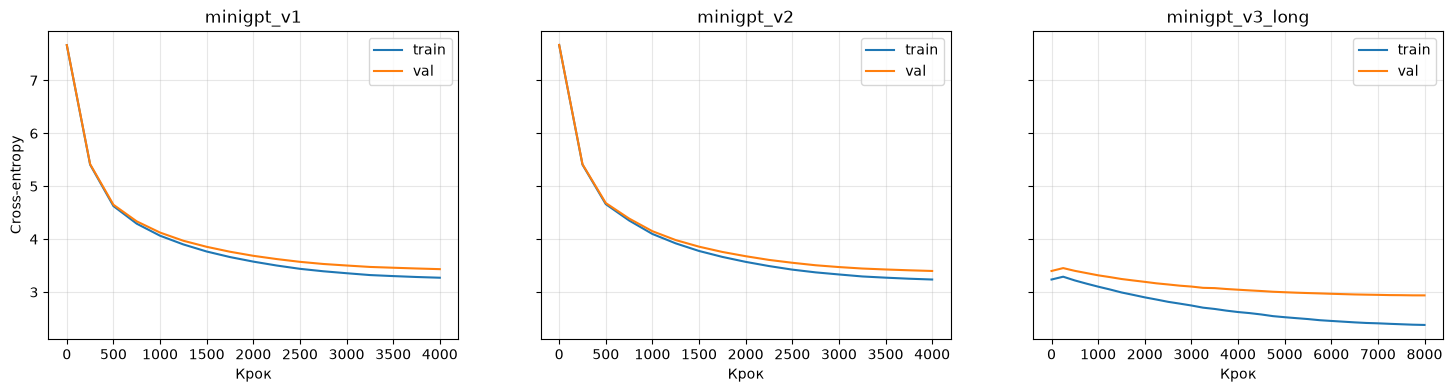

minigpt_v1 | В Україні в Києві: де найкращий фільм про запустив по Україні
minigpt_v1 | У Києві працюють ППО
minigpt_v1 | Українські науковці в Києві: де найкращий фільм проєктів
minigpt_v2 | В Україні всючих у більшості областей
minigpt_v2 | У Києві в Києві та області
minigpt_v2 | Українські науковці в Києві та області
minigpt_v3_long | В Україні з’явився новий спосіб
minigpt_v3_long | У Києві вдруге запас води: що відбувається
minigpt_v3_long | Українські науковці впали на полон росіянина, який випустив із із "атакою"


**За val loss переміг minigpt_v3_long: 2.937, perplexity 18.86.** Зменшення loss від глибини (v1→v2): 0.034; від додаткового навчання з новим LR-циклом (v2→v3): 0.461. Додатне значення означає покращення. Для v1/v2 змінювалася лише глибина; v3 оцінює додатковий бюджет і цикл навчання разом. Це не доводить перевагу для всіх seed/корпусів.

minigpt_v1 : best == last: True | найкращий крок: 4000
minigpt_v2 : best == last: True | найкращий крок: 4000
minigpt_v3_long : best == last: True | найкращий крок: 8000
Якість тексту оцінюємо за наведеними генераціями; менший loss сам по собі не гарантує фактичного чи граматично бездоганного заголовка.


,temperature,top_k,prompt,text
0,0.40,10,В Україні,В Україні з’явився новий дрон-перехоплювач
1,0.40,10,У Києві,У Києві вдруге за ніч оголошували повітряну тр...
2,0.40,10,Українські науковці,"Українські науковці впали на полон росіянина, ..."
3,0.55,10,В Україні,В Україні з’явився новий спосіб
4,0.55,10,У Києві,У Києві вдруге запас води: що відбувається
5,0.55,10,Українські науковці,"Українські науковці впали на полон росіянина, ..."
6,0.70,10,В Україні,В Україні з’явився новий спосіб
7,0.70,10,У Києві,У Києві вдруге запахує тіло на грибоків
8,0.70,10,Українські науковці,"Українські науковці впали на полон росіянина, ..."


In [ ]:
fig, axes = plt.subplots(1, len(histories), figsize=(6*len(histories), 4), sharey=True)
for ax, (name, history) in zip(axes, histories.items()):
    h = pd.DataFrame(history)
    ax.plot(h.step, h.train, label='train'); ax.plot(h.step, h.val, label='val')
    ax.set_title(name); ax.set_xlabel('Крок'); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel('Cross-entropy'); plt.show()
fig.savefig(REPORTS / 'learning_curves.png', dpi=150, bbox_inches='tight')

def generate_headline(checkpoint, prompt, seed=42, temperature=.55, top_k=10):
    saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
    tok = Tokenizer.from_str(saved['tokenizer_json'])
    m = MiniGPT(**saved['config']).to(device); m.load_state_dict(saved['model'])
    ids = tok.encode(prompt).ids or [tok.token_to_id('<eos>')]
    set_seed(seed)
    output = m.generate(torch.tensor([ids], device=device), max_new_tokens=48, temperature=temperature, top_k=top_k)
    text = tok.decode(output[0].tolist())
    del m, saved
    cleanup()
    return text
samples = []
for name in histories:
    for prompt in ['В Україні', 'У Києві', 'Українські науковці']:
        text = generate_headline(MODELS / f'{name}.pt', prompt)
        samples.append({'model': name, 'prompt': prompt, 'text': text})
        print(name, '|', text)
dump_json(REPORTS / 'generations.json', samples)
table = pd.DataFrame(gpt_results)
winner = table.loc[table.val_loss.idxmin()]
depth_effect = gpt_results[0]['val_loss'] - gpt_results[1]['val_loss']
longer_effect = gpt_results[1]['val_loss'] - gpt_results[2]['val_loss']
display(Markdown(f"**За val loss переміг {winner.model}: {winner.val_loss:.3f}, perplexity {winner.perplexity:.2f}.** Зменшення loss від глибини (v1→v2): {depth_effect:.3f}; від додаткового навчання з новим LR-циклом (v2→v3): {longer_effect:.3f}. Додатне значення означає покращення. Для v1/v2 змінювалася лише глибина; v3 оцінює додатковий бюджет і цикл навчання разом. Це не доводить перевагу для всіх seed/корпусів."))
for r in gpt_results:
    same = r['best_step'] == r['last_step']
    print(r['model'], ': best == last:', same, '| найкращий крок:', r['best_step'])
print('Якість тексту оцінюємо за наведеними генераціями; менший loss сам по собі не гарантує фактичного чи граматично бездоганного заголовка.')
sampling_rows = []
for temperature in (.4, .55, .7):
    for prompt in ['В Україні', 'У Києві', 'Українські науковці']:
        text = generate_headline(MODELS / f'{winner.model}.pt', prompt, temperature=temperature, top_k=10)
        sampling_rows.append({'temperature': temperature, 'top_k': 10, 'prompt': prompt, 'text': text})
display(pd.DataFrame(sampling_rows))
dump_json(REPORTS / 'sampling_comparison.json', sampling_rows)


Найкращий результат отримав `minigpt_v3_long`: `val_loss = 2.939`, проти `3.435` у v1 та `3.400` у v2. Збільшення глибини дало покращення приблизно на 0.035, а додаткове навчання з новим циклом learning rate — на 0.461. У v3 вже є зв’язний заголовок «В Україні з’явилися графіки відключень світла», проте інші продовження залишаються уривчастими або семантично хибними. Отже, нижчий loss супроводжується частковим покращенням тексту, але якість ще нестабільна.


interval_250:    0/500, train=7.665, val=7.666, 0.0 хв
interval_250:  250/500, train=5.652, val=5.660, 0.1 хв
interval_250:  500/500, train=5.209, val=5.218, 0.3 хв
interval_50:    0/500, train=7.665, val=7.666, 0.0 хв
interval_50:   50/500, train=7.066, val=7.061, 0.0 хв
interval_50:  100/500, train=6.697, val=6.686, 0.1 хв
interval_50:  150/500, train=6.401, val=6.399, 0.1 хв
interval_50:  200/500, train=5.962, val=5.964, 0.1 хв
interval_50:  250/500, train=5.652, val=5.660, 0.2 хв
interval_50:  300/500, train=5.468, val=5.475, 0.2 хв
interval_50:  350/500, train=5.352, val=5.360, 0.3 хв
interval_50:  400/500, train=5.283, val=5.289, 0.3 хв
interval_50:  450/500, train=5.239, val=5.248, 0.3 хв
interval_50:  500/500, train=5.209, val=5.218, 0.4 хв


,interval,seconds,eval_seconds,val_loss
0,250,16.784241,1.14212,5.217935
1,50,21.869615,4.32196,5.217935


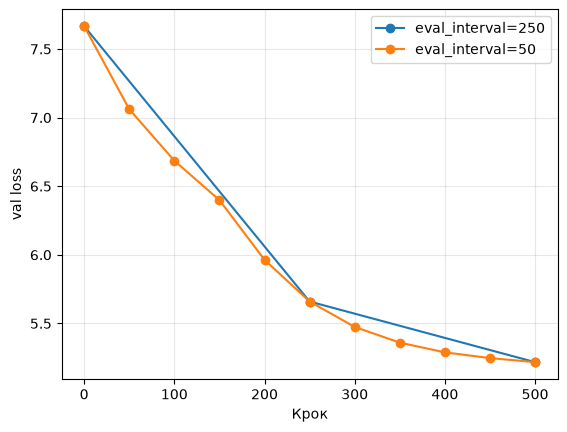

Різниця повного часу: 5.1 с; часу eval: 3.2 с.
Додаткових eval forward-батчів: 320
Повний wall time залежить також від прогріву GPU та фонових процесів; для чистішої оцінки варто повторити у зворотному порядку.


In [ ]:
interval_results, interval_histories = [], {}
for interval in (250, 50):
    r, h = train_variant(f'interval_{interval}', 2, steps=500, eval_interval=interval)
    interval_results.append(dict(interval=interval, **r)); interval_histories[interval] = h
display(pd.DataFrame(interval_results)[['interval', 'seconds', 'eval_seconds', 'val_loss']])
for interval, history in interval_histories.items():
    h = pd.DataFrame(history); plt.plot(h.step, h.val, marker='o', label=f'eval_interval={interval}')
plt.legend(); plt.grid(alpha=.3); plt.xlabel('Крок'); plt.ylabel('val loss'); plt.show()
a, b = interval_results
print(f"Різниця повного часу: {b['seconds']-a['seconds']:.1f} с; часу eval: {b['eval_seconds']-a['eval_seconds']:.1f} с.")
print('Додаткових eval forward-батчів:', 2 * EVAL_ITERS * (len(interval_histories[50]) - len(interval_histories[250])))
print('Повний wall time залежить також від прогріву GPU та фонових процесів; для чистішої оцінки варто повторити у зворотному порядку.')
dump_json(REPORTS / 'eval_interval.json', interval_results)


---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

### 4.0. Запустіть приклади виконання різних NLP задач

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [ ]:
# Звільняємо корпус і тензори; наступні секції використовують лише готові моделі.
del train_data, val_data, corpus_text, train_texts, val_texts, titles, small_texts
cleanup()
playground = {}
p = make_pipe('sentiment-analysis', MODEL_IDS['sentiment'])
playground['sentiment'] = p(["I've been waiting for this course my whole life.", 'I hate this so much!',
                             'Новий застосунок зручний, користуюся із задоволенням!', 'Оновлення зламало пошук, я дуже незадоволений.'])
display(playground['sentiment']); del p; cleanup()

p = make_pipe('zero-shot-classification', MODEL_IDS['zero_small'])
playground['zero_en'] = p('This is a course about Transformers.', candidate_labels=['education', 'politics', 'business'])
playground['zero_uk'] = p('Студенти створили нейромережу для розпізнавання української мови.',
    candidate_labels=['освіта', 'спорт', 'економіка', 'технології'], hypothesis_template='Цей текст про {}.')
display(playground['zero_en']); display(playground['zero_uk']); del p; cleanup()

p = make_pipe('fill-mask', MODEL_IDS['mask'])
playground['mask_en'] = p('This course will teach you about <mask> models.', top_k=3)
playground['mask_uk'] = p('Студенти читають книжки в <mask>.', top_k=3)
display(playground['mask_en']); display(playground['mask_uk']); del p; cleanup()

p = make_pipe('ner', MODEL_IDS['ner'], aggregation_strategy='simple')
playground['ner_en'] = p('My name is Sylvain and I work at Hugging Face in Brooklyn.')
playground['ner_uk'] = p('Леся Українка народилася у Звягелі, а Тарас Шевченко навчався в Петербурзі.')
display(playground['ner_en']); display(playground['ner_uk']); del p; cleanup()

# TAPAS — CPU: таблиця маленька, немає користі тримати GPU для неї.
p = pipeline('table-question-answering', model=MODEL_IDS['table'], device=-1)
en_table = pd.DataFrame({'Repository': ['Transformers', 'Datasets', 'Tokenizers'], 'Stars': ['36542', '4512', '3934']})
uk_table = pd.DataFrame({'Гурток': ['Робототехніка', 'Програмування', 'Шахи'], 'Учасники': ['18', '25', '12']})
playground['table_en'] = p(table=en_table, query='How many stars does Transformers have?')
playground['table_uk_direct'] = p(table=uk_table, query='Скільки учасників у гуртку Програмування?')
playground['table_uk_expected'] = '25'
playground['table_uk_control'] = p(table=pd.DataFrame({'Club': ['Robotics', 'Programming', 'Chess'], 'Members': ['18', '25', '12']}),
                                  query='How many members are in Programming?')
display({k:v for k,v in playground.items() if k.startswith('table')})
print('Прямий український результат порівняйте з еталонними 25; помилка тут показує мовне обмеження TAPAS.')
del p; cleanup()


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

Device set to use cpu
/usr/local/lib/python3.13/dist-packages/transformers/models/tapas/tokenization_tapas.py:2700: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  text = normalize_for_match(row[col_index].text)
/usr/local/lib/python3.13/dist-packages/transformers/models/tapas/tokenization_tapas.py:1494: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  cell = row[col_index]


{'table_en': {'answer': 'SUM > 36542',
  'coordinates': [(0, 1)],
  'cells': ['36542'],
  'aggregator': 'SUM'},
 'table_uk_direct': {'answer': 'Програмування',
  'coordinates': [(1, 0)],
  'cells': ['Програмування'],
  'aggregator': 'NONE'},
 'table_uk_expected': '25',
 'table_uk_control': {'answer': 'SUM > 25',
  'coordinates': [(1, 1)],
  'cells': ['25'],
  'aggregator': 'SUM'}}

Прямий український результат порівняйте з еталонними 25; помилка тут показує мовне обмеження TAPAS.


In [ ]:
# Шоста задача: генерація + temperature/top-p та thinking із питань до демо.
generation_dtype = torch.float16 if device.type == 'cuda' else torch.float32
p = make_pipe('text-generation', MODEL_IDS['generation'], torch_dtype=generation_dtype)
playground['generation_en'] = p('In this course, we will teach you how to', max_new_tokens=35,
                               do_sample=True, temperature=.8, top_p=.9, return_full_text=False)
display(playground['generation_en'])
def chat_generate(text, thinking=False, temperature=.7, top_p=.9, max_new_tokens=160):
    rendered = p.tokenizer.apply_chat_template([{'role': 'user', 'content': text}],
        tokenize=False, add_generation_prompt=True, enable_thinking=thinking)
    set_seed(SEED); sync(); t = time.perf_counter()
    out = p(rendered, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature,
            top_p=top_p, return_full_text=False)[0]['generated_text']
    sync()
    return {'text': out, 'seconds': time.perf_counter()-t, 'tokens': len(p.tokenizer.encode(out)),
            'thinking': thinking, 'temperature': temperature, 'top_p': top_p}
prompt = 'Придумай один короткий заголовок українською про відкриття студентської лабораторії робототехніки. Лише заголовок.'
generation_experiments = []
for temp, top_p in [(.2, .1), (.8, .6), (1.4, .8)]:
    result = chat_generate(prompt, temperature=temp, top_p=top_p)
    generation_experiments.append(result); display(result)
thinking_results = [chat_generate('Скільки буде 17 * 23? Дай коротку відповідь українською.', thinking=flag) for flag in (False, True)]
display(pd.DataFrame(thinking_results))
print('У true перевірте наявність блоку міркування та завершення відповіді; бюджет 160 токенів однаковий, але може бути замалим для thinking.')
if '<think>' in thinking_results[1]['text'] and '</think>' not in thinking_results[1]['text']:
    print('У цьому прогоні thinking=True вичерпав бюджет усередині блоку міркування: завершеної фінальної відповіді немає. False дав коротку відповідь без цього блоку.')
# Додаткова українська альтернатива до англомовної TAPAS: генеративний Table QA.
# Це text-generation pipeline з таблицею в контексті, а не нативна TAPAS.
uk_table_prompt = ('За таблицею дай лише число. Гурток | Учасники\n'
                   'Робототехніка | 18\nПрограмування | 25\nШахи | 12\n'
                   'Скільки учасників у гуртку Програмування?')
playground['table_uk_generative'] = chat_generate(uk_table_prompt, temperature=.2, top_p=.9, max_new_tokens=32)
display(playground['table_uk_generative'])
playground['generation_uk'] = generation_experiments
dump_json(REPORTS / 'playground.json', playground)
dump_json(REPORTS / 'thinking.json', thinking_results)
del p
cleanup()


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Device set to use cuda:0


...

{'text': 'Студентська лабораторія робототехніки',
 'seconds': 2.4999777309999445,
 'tokens': 19,
 'thinking': False,
 'temperature': 0.8,
 'top_p': 0.6}

{'text': 'Студенческий сабак тіла лабораторії робототехніки',
 'seconds': 3.5655992039996818,
 'tokens': 26,
 'thinking': False,
 'temperature': 1.4,
 'top_p': 0.8}

,text,seconds,tokens,thinking,temperature,top_p
0,17 * 23 = 391.,0.661600,12,False,0.7,0.9
1,"<think>\nOkay, the user is asking how many tim...",8.095588,160,True,0.7,0.9


У true перевірте наявність блоку міркування та завершення відповіді; бюджет 160 токенів однаковий, але може бути замалим для thinking.
У цьому прогоні thinking=True вичерпав бюджет усередині блоку міркування: завершеної фінальної відповіді немає. False дав коротку відповідь без цього блоку.


{'text': 'Учасників у гуртку Програмування є **25**.',
 'seconds': 1.1731523380003637,
 'tokens': 22,
 'thinking': False,
 'temperature': 0.2,
 'top_p': 0.9}

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [ ]:
import evaluate
LABELS = ['освіта', 'спорт', 'економіка', 'технології']
examples_by_label = {
 'освіта': ['Університет відкрив набір на магістерську програму.', 'Школярі складатимуть підсумковий іспит у червні.',
            'Учителі обговорили нову навчальну програму для п’ятого класу.', 'Студенти отримали стипендії за успіхи в навчанні.', 'Бібліотека коледжу придбала підручники для першокурсників.'],
 'спорт': ['Українська команда виграла фінал футбольного турніру.', 'Плавчиня встановила рекорд на чемпіонаті Європи.',
           'Баскетболісти перемогли суперника з різницею у десять очок.', 'Тенісистка вийшла до півфіналу після трьох сетів.', 'Марафонці готуються до забігу на сорок два кілометри.'],
 'економіка': ['Національний банк знизив облікову ставку.', 'Річна інфляція сповільнилася до п’яти відсотків.',
              'Підприємства збільшили експорт товарів до Євросоюзу.', 'Міністерство фінансів оприлюднило звіт про доходи бюджету.', 'Ціни на пальне зросли через подорожчання нафти.'],
 'технології': ['Компанія представила новий процесор для ноутбуків.', 'Розробники випустили оновлення операційної системи.',
               'Інженери створили робота для сортування посилок.', 'Програмісти виправили вразливість у браузері.', 'Стартап розробив нейромережу для розпізнавання голосу.']}
eval_rows = [{'text': text, 'label': label, 'split': 'calibration' if i < 2 else 'holdout'}
             for label, texts in examples_by_label.items() for i, text in enumerate(texts)]
eval_df = pd.DataFrame(eval_rows)
eval_df.to_csv(REPORTS / 'classification_examples.csv', index=False)
accuracy_metric = evaluate.load('accuracy')
def score_predictions(outputs, indices, threshold=0.):
    truth = [LABELS.index(eval_rows[i]['label']) for i in indices]
    pred = [LABELS.index(outputs[i]['labels'][0]) if outputs[i]['scores'][0] >= threshold else -1 for i in indices]
    accepted = [i for i, label in enumerate(pred) if label != -1]
    accuracy = accuracy_metric.compute(predictions=pred, references=truth)['accuracy']
    selective = accuracy_metric.compute(predictions=[pred[i] for i in accepted], references=[truth[i] for i in accepted])['accuracy'] if accepted else float('nan')
    return {'accuracy': accuracy, 'coverage': len(accepted)/len(indices), 'accepted_accuracy': selective}

all_outputs, comparison = {}, []
texts = eval_df.text.tolist()
for key in ('zero_small', 'zero_base'):
    p = make_pipe('zero-shot-classification', MODEL_IDS[key])
    kwargs = dict(candidate_labels=LABELS, hypothesis_template='Цей текст про {}.', multi_label=False, batch_size=8)
    p(texts[:2], **kwargs); sync()
    times = []
    for repeat in range(3):
        sync(); begin = time.perf_counter(); outputs = p(texts, **kwargs); sync()
        times.append(time.perf_counter()-begin)
    all_outputs[key] = outputs
    for split in ('calibration', 'holdout'):
        indices = eval_df.index[eval_df.split == split].tolist()
        comparison.append({'section': 'zero_shot', 'model': key, 'model_id': MODEL_IDS[key], 'split': split,
            'threshold': 0., 'parameters': sum(x.numel() for x in p.model.parameters()),
            'parameter_MiB': sum(x.numel()*x.element_size() for x in p.model.parameters()) / 2**20,
            'seconds_per_text': np.median(times)/len(texts), **score_predictions(outputs, indices)})
    del p; cleanup()
comparison_df = pd.DataFrame(comparison)
display(comparison_df)
calibration = comparison_df[comparison_df.split == 'calibration']
chosen = calibration.sort_values(['accuracy', 'parameters'], ascending=[False, True]).iloc[0]['model']
threshold_rows = []
for threshold in (0., .4, .6, .8):
    indices = eval_df.index[eval_df.split == 'calibration'].tolist()
    threshold_rows.append({'section': 'threshold', 'model': chosen, 'split': 'calibration', 'threshold': threshold,
                           **score_predictions(all_outputs[chosen], indices, threshold)})
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
# За однакової загальної accuracy обираємо більший поріг: більше обережності без втрати accuracy на calibration.
chosen_threshold = float(threshold_df.sort_values(['accuracy', 'threshold'], ascending=False).iloc[0].threshold)
indices = eval_df.index[eval_df.split == 'holdout'].tolist()
holdout_result = {'section': 'threshold', 'model': chosen, 'split': 'holdout', 'threshold': chosen_threshold,
                  **score_predictions(all_outputs[chosen], indices, chosen_threshold)}
display(pd.DataFrame([holdout_result]))
prediction_table = eval_df.copy()
for key, outputs in all_outputs.items():
    prediction_table[key] = [r['labels'][0] for r in outputs]
    prediction_table[key + '_confidence'] = [r['scores'][0] for r in outputs]
display(prediction_table)
prediction_table.to_csv(REPORTS / 'classification_predictions.csv', index=False)
results_df = pd.concat([pd.DataFrame(gpt_results), comparison_df, threshold_df, pd.DataFrame([holdout_result])], ignore_index=True)
results_df.to_csv(BASE / 'results.csv', index=False)
dump_json(REPORTS / 'app_choice.json', {'model': chosen, 'model_id': MODEL_IDS[chosen], 'threshold': chosen_threshold})
display(Markdown(f"**На calibration обрано {chosen}, поріг {chosen_threshold:.1f}.** На відкладених 12 прикладах accuracy={holdout_result['accuracy']:.1%}, coverage={holdout_result['coverage']:.1%}. Розмах calibration accuracy між моделями: {calibration.accuracy.max()-calibration.accuracy.min():.1%}; між порогами: {threshold_df.accuracy.max()-threshold_df.accuracy.min():.1%}. Це мала авторська вибірка: один holdout-приклад змінює accuracy на 8.3 в.п.; результат не є загальною оцінкою українського NLP."))


Device set to use cuda:0


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/558M [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

...

,section,model,model_id,split,threshold,parameters,parameter_MiB,seconds_per_text,accuracy,coverage,accepted_accuracy
0,zero_shot,zero_small,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,calibration,0.0,106995075,408.153820,0.004557,1.000000,1.0,1.000000
1,zero_shot,zero_small,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,holdout,0.0,106995075,408.153820,0.004557,0.833333,1.0,0.833333
2,zero_shot,zero_base,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,calibration,0.0,278811651,531.791021,0.014949,0.875000,1.0,0.875000
3,zero_shot,zero_base,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,holdout,0.0,278811651,531.791021,0.014949,0.750000,1.0,0.750000


,section,model,split,threshold,accuracy,coverage,accepted_accuracy
0,threshold,zero_small,calibration,0.0,1.000,1.000,1.0
1,threshold,zero_small,calibration,0.4,1.000,1.000,1.0
2,threshold,zero_small,calibration,0.6,0.750,0.750,1.0
3,threshold,zero_small,calibration,0.8,0.625,0.625,1.0


,section,model,split,threshold,accuracy,coverage,accepted_accuracy
0,threshold,zero_small,holdout,0.4,0.833333,1.0,0.833333


,text,label,split,zero_small,zero_small_confidence,zero_base,zero_base_confidence
0,Університет відкрив набір на магістерську прог...,освіта,calibration,освіта,0.542345,освіта,0.998491
1,Школярі складатимуть підсумковий іспит у червні.,освіта,calibration,освіта,0.958457,освіта,0.988714
2,Учителі обговорили нову навчальну програму для...,освіта,holdout,освіта,0.935164,освіта,0.999380
3,Студенти отримали стипендії за успіхи в навчанні.,освіта,holdout,освіта,0.932787,освіта,0.998160
4,Бібліотека коледжу придбала підручники для пер...,освіта,holdout,освіта,0.957333,освіта,0.999415
5,Українська команда виграла фінал футбольного т...,спорт,calibration,спорт,0.962596,спорт,0.915686
6,Плавчиня встановила рекорд на чемпіонаті Європи.,спорт,calibration,спорт,0.457505,спорт,0.810153
7,Баскетболісти перемогли суперника з різницею у...,спорт,holdout,спорт,0.645096,спорт,0.876692
8,Тенісистка вийшла до півфіналу після трьох сетів.,спорт,holdout,спорт,0.545996,спорт,0.957410
9,Марафонці готуються до забігу на сорок два кіл...,спорт,holdout,спорт,0.554574,освіта,0.512879


**На calibration обрано zero_small, поріг 0.4.** На відкладених 12 прикладах accuracy=83.3%, coverage=100.0%. Розмах calibration accuracy між моделями: 12.5%; між порогами: 37.5%. Це мала авторська вибірка: один holdout-приклад змінює accuracy на 8.3 в.п.; результат не є загальною оцінкою українського NLP.

За calibration-вибіркою перемогла MiniLM: accuracy 100% проти 87.5% у mDeBERTa. На відкладених 12 реченнях вона дала 83.3% проти 75%. Обраний поріг 0.4 не змінив accuracy та coverage порівняно з відсутністю порога; пороги 0.6 і 0.8 збільшили кількість відмов і знизили загальну accuracy. На цій вибірці підбір порога не покращив результат відносно базового, тоді як вибір моделі дав різницю. Вибірка мала, тому ці значення не є загальною оцінкою українського NLP.


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [ ]:
import gradio as gr
app_choice = json.loads((REPORTS / 'app_choice.json').read_text(encoding='utf-8'))
app_classifier = make_pipe('zero-shot-classification', app_choice['model_id'])
def sort_news(text, threshold):
    lines = [x.strip() for x in text.splitlines() if x.strip()][:30]
    if not lines: return pd.DataFrame(columns=['Заголовок', 'Рубрика', 'Впевненість']), 'Додайте хоча б один заголовок.'
    if any(len(x) > 1000 for x in lines): raise gr.Error('Один заголовок має бути коротшим за 1000 символів.')
    outputs = app_classifier(lines, candidate_labels=LABELS, hypothesis_template='Цей текст про {}.', multi_label=False, batch_size=8)
    rows = [{'Заголовок': line, 'Рубрика': r['labels'][0] if r['scores'][0] >= threshold else 'Перевірити вручну',
             'Впевненість': round(r['scores'][0], 3)} for line, r in zip(lines, outputs)]
    frame = pd.DataFrame(rows)
    summary = ' · '.join(f'{label}: {count}' for label, count in frame['Рубрика'].value_counts().items())
    return frame, summary
smoke_frame, smoke_summary = sort_news('Університет відкрив нову навчальну програму.\nКоманда виграла футбольний матч.', app_choice['threshold'])
assert len(smoke_frame) == 2 and set(smoke_frame.columns) == {'Заголовок', 'Рубрика', 'Впевненість'}
display(smoke_frame)
with gr.Blocks(title='Редактор новинної стрічки') as app:
    gr.Markdown('# Редактор новинної стрічки\nРозподіліть заголовки між рубриками. Невпевнені випадки перевірте вручну. До 30 заголовків за раз.')
    news_input = gr.Textbox(label='Заголовки — кожен із нового рядка', lines=7,
        value='Студенти отримали стипендії за успіхи в навчанні.\nКоманда перемогла у фіналі чемпіонату.\nІнженери представили новий процесор.')
    threshold_input = gr.Slider(0, 1, value=app_choice['threshold'], step=.05, label='Поріг впевненості')
    run_button = gr.Button('Розподілити новини', variant='primary')
    output_table = gr.Dataframe(label='Результат', interactive=False)
    output_summary = gr.Textbox(label='Зведення', interactive=False)
    run_button.click(sort_news, [news_input, threshold_input], [output_table, output_summary])
app.launch(share=IN_COLAB, inline=True, prevent_thread_lock=True, show_error=True)


Device set to use cuda:0


,Заголовок,Рубрика,Впевненість
0,Університет відкрив нову навчальну програму.,освіта,0.537
1,Команда виграла футбольний матч.,спорт,0.957


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f536702792a9156c3a.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import zipfile
archive = BASE / 'delivery.zip'
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for path in BASE.rglob('*'):
        if not path.is_file() or 'cache' in path.relative_to(BASE).parts or path == archive or path.name.endswith('_last.pt'):
            continue
        z.write(path, 'lab3/' + path.relative_to(BASE).as_posix())
print('Архів:', archive.resolve(), '|', round(archive.stat().st_size/2**20, 1), 'MiB')
display(results_df)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive))
else:
    from IPython.display import FileLink
    display(FileLink(str(archive)))


Архів: /content/drive/MyDrive/ai_systems/lab3/delivery.zip | 36.6 MiB


,section,model,layers,parameters,val_loss,perplexity,best_step,last_step,seconds,eval_seconds,initialized_from,model_id,split,threshold,parameter_MiB,seconds_per_text,accuracy,coverage,accepted_accuracy
0,mini_gpt,minigpt_v1,2.0,1689728.0,3.432719,30.960725,4000.0,4000.0,135.411839,6.806775,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,mini_gpt,minigpt_v2,4.0,2578304.0,3.398328,29.914044,4000.0,4000.0,247.835897,11.364043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,mini_gpt,minigpt_v3_long,4.0,2578304.0,2.936996,18.859115,8000.0,8000.0,490.509539,21.540512,minigpt_v2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,zero_shot,zero_small,NaN,106995075.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,calibration,0.0,408.153820,0.004557,1.000000,1.000,1.000000
4,zero_shot,zero_small,NaN,106995075.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,holdout,0.0,408.153820,0.004557,0.833333,1.000,0.833333
5,zero_shot,zero_base,NaN,278811651.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,calibration,0.0,531.791021,0.014949,0.875000,1.000,0.875000
6,zero_shot,zero_base,NaN,278811651.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,holdout,0.0,531.791021,0.014949,0.750000,1.000,0.750000
7,threshold,zero_small,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,calibration,0.0,NaN,NaN,1.000000,1.000,1.000000
8,threshold,zero_small,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,calibration,0.4,NaN,NaN,1.000000,1.000,1.000000
9,threshold,zero_small,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,calibration,0.6,NaN,NaN,0.750000,0.750,1.000000


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```